# 01 · Comprensión de los datos y calidad

**Responsable:** Integrante A · **Plan:** ver `PLAN.md`

Describir el dataset, verificar su calidad y documentar las decisiones de limpieza 1 a 5.

## Preparación

In [27]:
from pathlib import Path
import sys

# Busca la raíz del repo (la carpeta que contiene src/) sin importar desde dónde se abra el notebook.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import importlib
importlib.reload(limpieza)

sns.set_theme(style="whitegrid")  # estilo común para todas las figuras del proyecto

from src import contratos, rutas
from src import carga, limpieza

## 1. Comprensión de los datos

- **Procedencia y licencia:**  MovieLens `ml-latest-small`, publicado por GroupLens (Universidad de Minnesota) y generado el 26 de septiembre de 2018 (<https://grouplens.org/datasets/movielens/latest/>). Se puede usar para investigación sin fines comerciales, sin implicar respaldo de la universidad; se puede redistribuir (incluidas transformaciones) bajo las mismas condiciones y hay que citar a Harper & Konstan (2015). La cita y la licencia están en el `README.md`.
- **Contexto en que se generaron los datos:** Son calificaciones hechas en [MovieLens](https://movielens.org), un servicio de recomendación de películas operado por GroupLens. 610 usuarios fueron elegidos al azar entre quienes habían calificado al menos 20 películas; sus ratings van de marzo de 1996 a septiembre de 2018. No hay datos demográficos: cada usuario es solo un id. Es un conjunto de *desarrollo*, no de referencia.
- **Variables de cada tabla y unidad de observación:** 
   - `ratings`: `userId`, `movieId`, `rating` (de 0.5 a 5.0 en pasos de 0.5) y `timestamp` (segundos desde 1970 en UTC). **Una fila es una calificación** (usuario × película).
   - `movies`: `movieId`, `title` (con el año de estreno entre paréntesis) y `genres` (géneros separados por `|`). **Una fila es una película.**

- **Por qué no usamos `links` y `tags`:** `links` solo enlaza los ids con IMDb y TMDb, y no aporta variables para nuestras preguntas. `tags` es texto libre de los usuarios, y limpiarlo requiere un trabajo que no cabe en el plazo; además solo tiene 3,683 etiquetas frente a 100,836 ratings.
- **Preguntas de investigación y por qué estos datos sirven para responderlas:** (1) ¿las películas con más calificaciones generan opiniones más divididas?, y (2) si a un usuario le gusta una película o un género (rating ≥ 4), ¿qué otras tienden a gustarle? Ambas se contestan con `ratings` (quién calificó qué y cuánto) y `movies` (título, año y géneros). Hay una limitación: los usuarios son una muestra autoseleccionada, así que no representan al público general.

## 2. Carga con tipos (decisión 1)

In [8]:
movies_raw = carga.cargar_movies()
ratings_raw = carga.cargar_ratings()
contratos.verificar_esquema(movies_raw, "movies_raw")
contratos.verificar_esquema(ratings_raw, "ratings_raw")

print(f"movies:  {movies_raw.shape[0]:,} filas x {movies_raw.shape[1]} columnas")
print(f"ratings: {ratings_raw.shape[0]:,} filas x {ratings_raw.shape[1]} columnas")
print(f"Usuarios distintos:  {ratings_raw['userId'].nunique():,}")
print(f"Películas distintas en movies: {movies_raw['movieId'].nunique():,}")

movies:  300 filas x 3 columnas
ratings: 8,492 filas x 4 columnas
Usuarios distintos:  120
Películas distintas en movies: 300


C:\Users\pauli\AppData\Local\Temp\ipykernel_22976\1158623674.py:1: UserWarning: cargar_movies() es un DUMMY: devuelve datos inventados con el esquema del contrato.
  movies_raw = carga.cargar_movies()
C:\Users\pauli\AppData\Local\Temp\ipykernel_22976\1158623674.py:2: UserWarning: cargar_ratings() es un DUMMY: devuelve datos inventados con el esquema del contrato.
  ratings_raw = carga.cargar_ratings()


In [13]:
movies_raw.head()

,movieId,title,genres
0,361,Película 000 (1990),(no genres listed)
1,522,Película 001 (2012),(no genres listed)
2,828,Película 002 (1993),(no genres listed)
3,2565,Película 003 (1966),Action|Children|Thriller
4,2570,Película 004 (1953),Thriller


In [ ]:
ratings_raw.head()

,userId,movieId,rating,timestamp
0,1,93047,3.0,892542560
1,1,23572,2.5,878223818
2,1,171343,5.0,1304256151
3,1,56422,4.5,853279949
4,1,62798,2.0,1439909224


In [ ]:
print("Tipos de movies:")
print(movies_raw.dtypes)
print("\nTipos de ratings:")
print(ratings_raw.dtypes)

Tipos de movies:
movieId    object
title      object
genres     object
dtype: object

Tipos de ratings:
userId        object
movieId       object
rating       float64
timestamp      int64
dtype: object


In [15]:
fechas = pd.to_datetime(ratings_raw["timestamp"], unit="s", utc=True)
print(f"Primera calificación: {fechas.min()}")
print(f"Última calificación:  {fechas.max()}")

Primera calificación: 1996-03-31 09:09:27+00:00
Última calificación:  2018-09-22 20:14:10+00:00


## 3. Validaciones



### 3.1 Valores Vacíos

In [ ]:
# Valores vacíos en ambas tablas
nulos_movies = movies_raw.isna().sum()
nulos_ratings = ratings_raw.isna().sum()

print("Valores vacíos en movies:")
print(nulos_movies)
print("\nValores vacíos en ratings:")
print(nulos_ratings)
print(f"\nTotal de vacíos: movies = {nulos_movies.sum()}, ratings = {nulos_ratings.sum()}")

Valores vacíos en movies:
movieId    0
title      0
genres     0
dtype: int64

Valores vacíos en ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Total de vacíos: movies = 0, ratings = 0


### 3.2 llaves

In [10]:
# llaves con limpieza.validar_llave: movieId en movies; (userId, movieId) en ratings
print('movieId en movies:', limpieza.validar_llave(movies_raw, ['movieId']))
print('(userId, movieId) en ratings:', limpieza.validar_llave(ratings_raw, ['userId', 'movieId']))

movieId en movies: {'es_llave': True, 'duplicados': 0, 'nulos': 0}
(userId, movieId) en ratings: {'es_llave': True, 'duplicados': 0, 'nulos': 0}


C:\Users\pauli\AppData\Local\Temp\ipykernel_22976\2802013265.py:2: UserWarning: validar_llave() es un DUMMY: devuelve datos inventados con el esquema del contrato.
  print('movieId en movies:', limpieza.validar_llave(movies_raw, ['movieId']))
C:\Users\pauli\AppData\Local\Temp\ipykernel_22976\2802013265.py:3: UserWarning: validar_llave() es un DUMMY: devuelve datos inventados con el esquema del contrato.
  print('(userId, movieId) en ratings:', limpieza.validar_llave(ratings_raw, ['userId', 'movieId']))


### 3.3 Valores de `rating`

In [30]:
# integridad entre tablas: ratings de películas inexistentes; películas sin ratings
ids_movies = set(movies_raw["movieId"])
ids_ratings = set(ratings_raw["movieId"])

ratings_huerfanos = ratings_raw[~ratings_raw["movieId"].isin(ids_movies)]
peliculas_sin_rating = movies_raw[~movies_raw["movieId"].isin(ids_ratings)]

print(f"Ratings de películas que no existen en movies: {len(ratings_huerfanos)}")
print(f"Películas sin ningún rating: {len(peliculas_sin_rating)}")
peliculas_sin_rating.head()

Ratings de películas que no existen en movies: 0
Películas sin ningún rating: 4


,movieId,title,genres
0,361,Película 000 (1990),(no genres listed)
50,35421,Película 050 (1971),Mystery|Western
61,45208,Película 061 (1960),Drama|Mystery|Sci-Fi
280,188042,Película 280 (1960),Adventure|Fantasy|Sci-Fi


### 3.4 `rating`

In [28]:
# rating dentro de {0.5, ..., 5.0}
valores_rating = [float(v) for v in sorted(ratings_raw['rating'].unique())]
print('Valores distintos de rating:', valores_rating)
print('¿Todos dentro de {0.5, 1.0, ..., 5.0}?', set(valores_rating) <= set(limpieza.RATINGS_VALIDOS))

print('Número de ratings por valor:')
ratings_raw['rating'].value_counts().sort_index()

Valores distintos de rating: [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
¿Todos dentro de {0.5, 1.0, ..., 5.0}? True
Número de ratings por valor:


0.5     113
1.0     255
1.5     148
2.0     626
2.5     470
3.0    1722
3.5    1136
4.0    2233
4.5     713
5.0    1076
Name: rating, dtype: int64

### 3.5 Rango de fecha

In [29]:
# rango de fechas (después de convertir timestamp)
fechas = pd.to_datetime(ratings_raw['timestamp'], unit='s', utc=True)
print('Primer rating:', fechas.min())
print('Último rating:', fechas.max())

Primer rating: 1996-03-31 09:09:27+00:00
Último rating: 2018-09-22 20:14:10+00:00


## 4. Géneros (decisiones 3 y 4)

In [31]:
#géneros únicos después de separar por '|'; comparar con la lista del README (IMAX, Children's)
generos_readme = [
    "Action", "Adventure", "Animation", "Children's", "Comedy", "Crime", "Documentary",
    "Drama", "Fantasy", "Film-Noir", "Horror", "Musical", "Mystery", "Romance",
    "Sci-Fi", "Thriller", "War", "Western", "(no genres listed)",
]
peliculas_por_genero = movies_raw['genres'].str.split('|').explode().value_counts()

print(f'Géneros distintos en los datos: {len(peliculas_por_genero)}')
print('En los datos pero NO en el README:', sorted(set(peliculas_por_genero.index) - set(generos_readme)))
print('En el README pero NO en los datos:', sorted(set(generos_readme) - set(peliculas_por_genero.index)))

print('='*50)
print('Películas por género (una película puede tener varios):')
print('='*50)
peliculas_por_genero

Géneros distintos en los datos: 20
En los datos pero NO en el README: ['Children', 'IMAX']
En el README pero NO en los datos: ["Children's"]
Películas por género (una película puede tener varios):


Western               43
Documentary           43
Film-Noir             42
Animation             41
Children              40
Romance               39
Action                38
Drama                 38
Crime                 38
Adventure             37
Comedy                37
Fantasy               35
War                   34
Musical               33
Mystery               32
Thriller              32
Sci-Fi                30
Horror                29
(no genres listed)    29
IMAX                  13
Name: genres, dtype: int64

In [32]:
# (no genres listed): número y % de películas; número y % de ratings ligados a ellas
sin_genero = movies_raw['genres'] == '(no genres listed)'
ratings_sin_genero = ratings_raw['movieId'].isin(movies_raw.loc[sin_genero, 'movieId'])

print(f'Películas sin género: {sin_genero.sum()} ({sin_genero.mean() * 100:.2f}% de las películas)')
print(f'Ratings de esas películas: {ratings_sin_genero.sum()} ({ratings_sin_genero.mean() * 100:.2f}% de los ratings)')

Películas sin género: 29 (9.67% de las películas)
Ratings de esas películas: 910 (10.72% de los ratings)


**Decisión:** …  
**Consecuencia:** …

## 5. Títulos (decisiones 2 y 5)

In [33]:
# títulos con espacios sobrantes; títulos sin año
con_espacios = movies_raw['title'] != movies_raw['title'].str.strip()
print(f'Títulos con espacios sobrantes: {con_espacios.sum()}')
print(movies_raw.loc[con_espacios, 'title'].map(repr).head(3).to_string(index=False))

# el año es lo último del título, entre paréntesis
patron_anio = r'\((\d{4})\)$'
sin_anio_sin_strip = movies_raw['title'].str.extract(patron_anio)[0].isna()
sin_anio = movies_raw['title'].str.strip().str.extract(patron_anio)[0].isna()
print('='*50)
print(f'Títulos sin año si NO se quitan antes los espacios: {sin_anio_sin_strip.sum()}')
print(f'Títulos sin año después de quitar los espacios: {sin_anio.sum()}')
print('='*50)
movies_raw.loc[sin_anio, ['movieId', 'title']]

Títulos con espacios sobrantes: 9
'Película 000 (1990) '
'Película 037 (1974) '
'Película 074 (2001) '
Títulos sin año si NO se quitan antes los espacios: 11
Títulos sin año después de quitar los espacios: 2


,movieId,title
10,6923,Película 010
20,15502,Película 020


In [ ]:
# títulos duplicados con movieId distinto: géneros de cada versión y usuarios que calificaron ambas
titulos = movies_raw.assign(title=movies_raw['title'].str.strip())
n_ids_por_titulo = titulos.groupby('title')['movieId'].nunique()
titulos_dup = n_ids_por_titulo[n_ids_por_titulo > 1].index
dup = titulos[titulos['title'].isin(titulos_dup)].sort_values(['title', 'movieId'])

print(f'Títulos con más de un movieId: {len(titulos_dup)}')
print('='*50)
print(dup[['movieId', 'title', 'genres']].to_string(index=False))

filas = []
for titulo in titulos_dup:
    ids = dup.loc[dup['title'] == titulo, 'movieId']
    versiones_por_usuario = ratings_raw[ratings_raw['movieId'].isin(ids)].groupby('userId')['movieId'].nunique()
    filas.append({
        'title': titulo,
        'movieIds': ', '.join(ids),
        'usuarios que calificaron ambas': int((versiones_por_usuario == 2).sum()),
    })

print('='*50)
print('Usuarios que calificaron las dos versiones de un mismo título:')
print('='*50)
print(pd.DataFrame(filas).to_string(index=False))

Títulos con más de un movieId: 1
movieId               title               genres
  27377 Película 040 (1928)              Fantasy
  29022 Película 040 (1928) Crime|Horror|Musical
Usuarios que calificaron las dos versiones de un mismo título:
              title     movieIds  usuarios que calificaron ambas
Película 040 (1928) 27377, 29022                               4


**Decisión:** …  
**Consecuencia:** …

## 6. Tablas limpias y forma general

In [35]:
movies = limpieza.movies_limpias(movies_raw)
ratings = limpieza.ratings_limpias(ratings_raw)
contratos.verificar_esquema(movies, "movies")
contratos.verificar_esquema(ratings, "ratings")

In [36]:
# número de usuarios, películas, ratings y géneros
print(f'Usuarios: {ratings.userId.nunique()}')
print(f'Películas en movies: {len(movies)} (con al menos un rating: {ratings.movieId.nunique()})')
print(f'Ratings: {len(ratings)}')
print(f'Géneros: {len(contratos.GENEROS)} (más la bandera es_imax)')
print(f'Periodo: {ratings.fecha.min():%Y-%m-%d} a {ratings.fecha.max():%Y-%m-%d}')

Usuarios: 120
Películas en movies: 300 (con al menos un rating: 296)
Ratings: 8492
Géneros: 18 (más la bandera es_imax)
Periodo: 1996-03-31 a 2018-09-22


In [37]:
# distribución de ratings por película y por usuario (describe); usuarios muy activos (atípicos que se conservan)
rev_por_pelicula = ratings.groupby('movieId').size()
rev_por_usuario = ratings.groupby('userId').size()

print('='*50)
print('Ratings por película:')
print('='*50)
print(rev_por_pelicula.describe(percentiles=[0.5, 0.9]).round(1))
print(f'(Películas con un solo rating: {(rev_por_pelicula == 1).sum()})')

print('='*50)
print('Ratings por usuario:')
print('='*50)
print(rev_por_usuario.describe(percentiles=[0.5, 0.9]).round(1))
print(f'(Los 10 usuarios más activos suman {rev_por_usuario.nlargest(10).sum() / len(ratings) * 100:.1f}% de los ratings)')

Ratings por película:
count    296.0
mean      28.7
std       25.5
min        1.0
50%       20.5
90%       66.0
max      119.0
dtype: float64
(Películas con un solo rating: 11)
Ratings por usuario:
count    120.0
mean      70.8
std       29.4
min       20.0
50%       75.0
90%      108.0
max      119.0
dtype: float64
(Los 10 usuarios más activos suman 13.5% de los ratings)


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


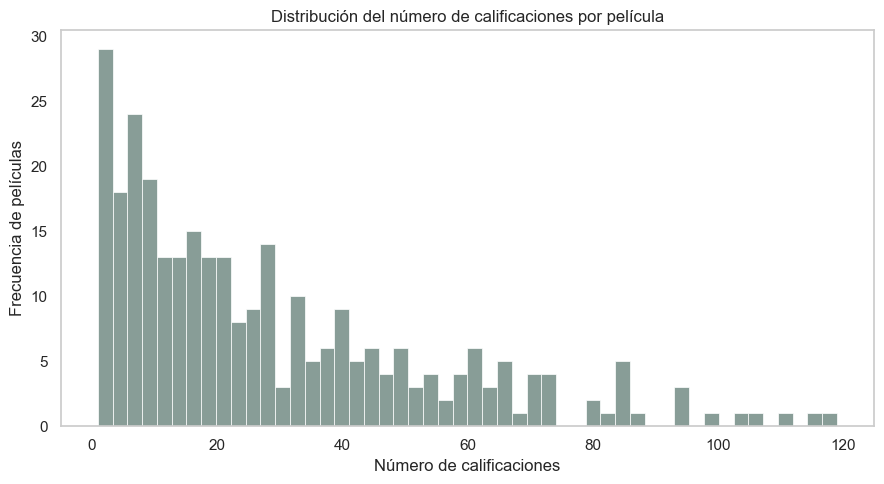

In [43]:
# gráfico de la distribución de ratings por película (muy asimétrica)
# rutas.guardar_figura(fig, "01_distribucion_ratings")
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    rev_por_pelicula,
    bins=50,
    color="#607D75",
    edgecolor="white",
    linewidth=0.5,
    ax=ax
)

ax.set(
    title="Distribución del número de calificaciones por película",
    xlabel="Número de calificaciones",
    ylabel="Frecuencia de películas"
)
ax.grid(False)
ax.legend(frameon=False)

plt.tight_layout()
rutas.guardar_figura(fig, "01_distribucion_ratings")
plt.show()

> **Interpretación**
> - *Qué muestra:* …
> - *Por qué es relevante:* …
> - *Limitaciones:* …

## 7. Bitácora de limpieza

Completar `results/tables/bitacora_limpieza.csv` (problema · evidencia · decisión · consecuencia) y mostrarla aquí.

In [42]:
pd.read_csv(rutas.TABLAS / "bitacora_limpieza.csv")

,id,problema,evidencia,decision,consecuencia
0,1,IDs leídos como número pueden aparecer como 'x...,PENDIENTE,Leer userId y movieId como str desde read_csv;...,PENDIENTE
1,2,Títulos duplicados con movieId distinto,PENDIENTE,No fusionar; movieId sigue siendo la llave; mo...,PENDIENTE
2,3,Películas con '(no genres listed)',PENDIENTE,No imputar; se conservan en análisis por pelíc...,PENDIENTE
3,4,IMAX en los datos pero no en el README (es un ...,PENDIENTE,Excluir IMAX de los géneros y guardarlo como b...,PENDIENTE
4,5,Títulos con espacios sobrantes y sin año,PENDIENTE,Quitar espacios antes de extraer el año; sin a...,PENDIENTE
5,6,Estadísticos por película poco confiables con ...,PENDIENTE,Umbral n >= 20 con análisis de sensibilidad (1...,PENDIENTE


## 8. Resumen

…